# A04-KM — Thuận

Phân công khớp chính xác mốc `2026-11-17T21:00:00.000Z` trong workbook nguồn.
Ngày giờ Việt Nam: **04:00 ngày 18/11/2026**. Mã thư mục giữ ngày của mốc UTC.

Cấu hình: `A04`, `KMeans`. Nguồn duy nhất:
`data/raw/Online Retail.xlsx`, SHA-256 `43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d`.

Notebook mặc định đọc kết quả đã chạy. Đổi `RUN_AGAIN = True` để dựng lại từ raw,
quét tham số và ghi lại **chỉ thư mục kết quả của thí nghiệm này**.
Mọi nhãn cụm gắn với CustomerID; Monetary là giá trị mua lịch sử GBP.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

REL = Path("project/experiments/thuan_deadline_2026_11_17")
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / REL]]
BASE = next(q for q in candidates if (q / "run_experiments.py").is_file())
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import run_experiments as runner


In [2]:
EXPERIMENT = "A04-KM"
RUN_AGAIN = False
if RUN_AGAIN:
    with threadpool_limits(limits=1):
        rfm, cleaning, provenance = runner.prepare_input()
        runner.run_one(EXPERIMENT, rfm)
        runner.workbook(runner.assignments(), rfm, cleaning, provenance)
OUT = BASE / "results" / EXPERIMENT
params = json.loads((OUT / "parameters.json").read_text(encoding="utf-8"))
assert params["status"] == "completed"
display(pd.Series({
    "Thí nghiệm": EXPERIMENT,
    "Mô hình": params["actual_model"],
    "Khách": params["customers"],
    "Số chiều đầu vào": params["preprocessing"]["model_input_dimensions"],
    "Biến đổi": params["preprocessing"]["transform"],
    "Scaler": params["preprocessing"]["scaler"],
    "PCA": params["preprocessing"]["pca_requested"],
}).to_frame("Giá trị"))
print(json.dumps(params["preprocessing"], ensure_ascii=False, indent=2))


,Giá trị
Thí nghiệm,A04-KM
Mô hình,KMeans
Khách,4327
Số chiều đầu vào,3
Biến đổi,none
Scaler,StandardScaler
PCA,0.95


{
  "configuration": "A04",
  "transform": "none",
  "scaler": "StandardScaler",
  "pca_requested": 0.95,
  "model_input_dimensions": 3,
  "pca_explained_variance_ratio": [
    0.5638240337173058,
    0.30163072566982435,
    0.13454524061286977
  ],
  "pca_explained_variance_total": 1.0,
  "pca_components": [
    [
      -0.37402340703988635,
      0.6748844371544975,
      0.6361112225648374
    ],
    [
      0.9112201331059055,
      0.13978679633999763,
      0.3874758322675827
    ],
    [
      0.17258145905262023,
      0.7245623838260283,
      -0.6672518204813022
    ]
  ]
}


## Quét tham số và lựa chọn
GN dùng GNN Graph Autoencoder hai lớp GCN rồi K-Means trên embedding học được. Silhouette GN tính trên embedding; KM tính trên PCA/scaler input; DBSCAN tính trên khách không nhiễu. Các không gian này không so trực tiếp. Checkpoint GNN chọn theo BCE validation, không theo test.

,Được chọn
k,2
n_clusters,2
noise_pct,0.0
smallest_cluster,24
largest_cluster_pct_all,99.445343
silhouette,0.899359
dbi,0.727462
chi,1947.521834
warnings,
inertia,8950.598577


,k,n_clusters,noise_pct,smallest_cluster,largest_cluster_pct_all,silhouette,dbi,chi,warnings,inertia,eligible
0,2,2,0.0,24,99.445343,0.899359,0.727462,1947.521834,NaN,8950.598577,True
1,3,3,0.0,24,74.324012,0.592067,0.694425,3052.737882,NaN,5381.848569,True
2,4,4,0.0,12,70.348972,0.615789,0.741640,3209.048781,NaN,4022.671993,True
3,5,5,0.0,3,67.691241,0.600067,0.653932,3590.574721,NaN,3002.728780,True
4,6,6,0.0,2,67.413913,0.597499,0.594587,3911.077668,NaN,2349.224078,True
5,7,7,0.0,2,60.272706,0.519572,0.604346,4210.628142,NaN,1895.617176,True
6,8,8,0.0,2,50.103998,0.479221,0.663308,4461.318081,NaN,1577.168881,True
7,9,9,0.0,2,49.896002,0.479148,0.693064,4705.242154,NaN,1335.844658,True
8,10,10,0.0,2,36.330021,0.423565,0.713331,4797.913475,NaN,1179.826707,True


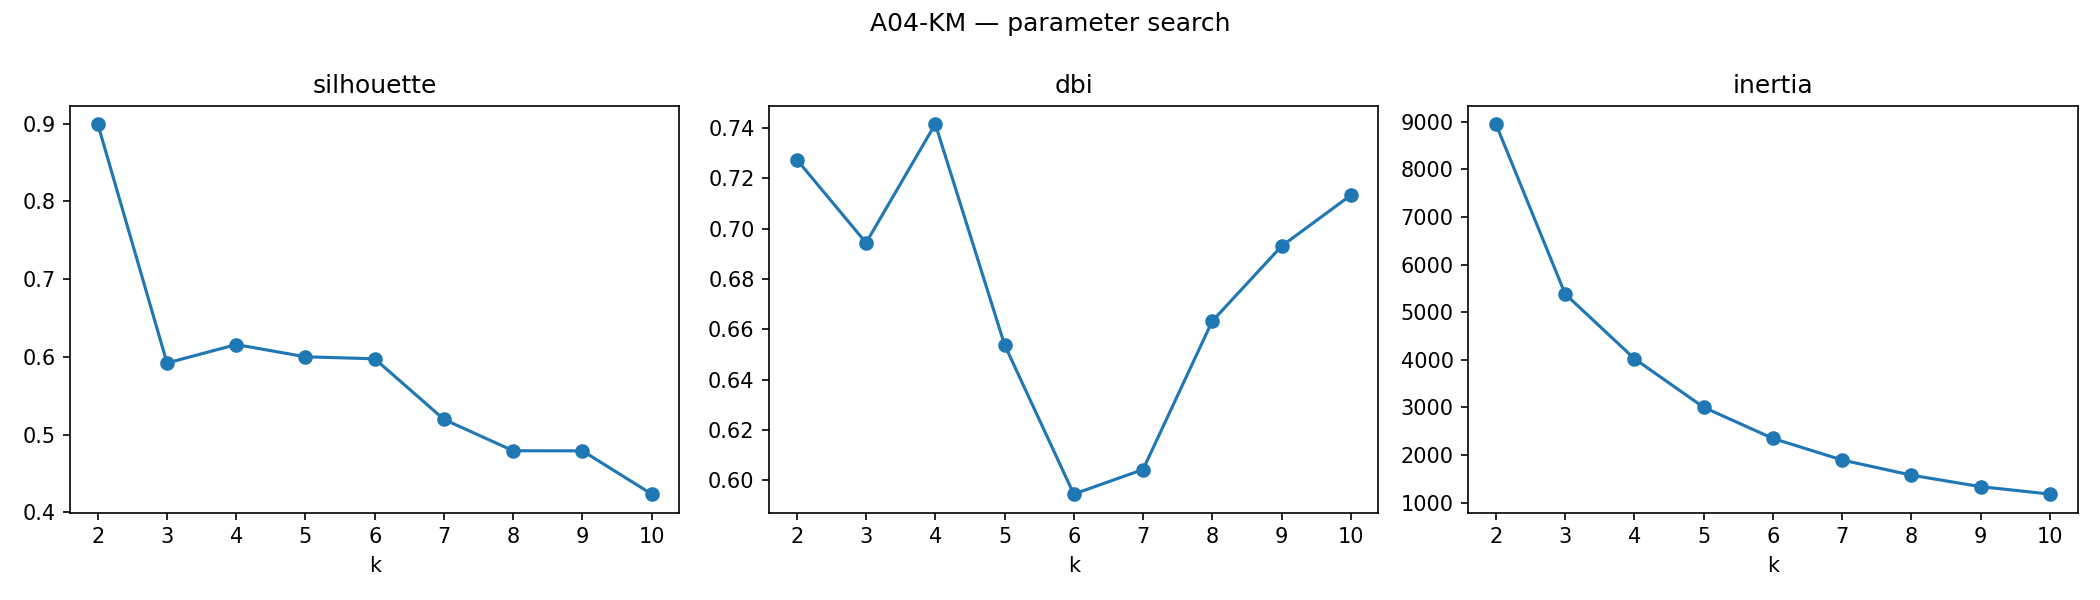

In [3]:
grid = pd.read_csv(OUT / "search.csv")
display(pd.Series(params["selected"]).to_frame("Được chọn"))
display(grid)
display(Image(filename=str(OUT / "figures" / "search.png")))
if "gnn_training" in params:
    print(json.dumps(params["gnn_training"], ensure_ascii=False, indent=2))
    display(Image(filename=str(OUT / "figures" / "training.png")))
    display(pd.read_csv(OUT / "training_history.csv"))


## Nhãn và hồ sơ cụm
Hình chỉ hiển thị hai tọa độ đầu; bảng RFM dùng đơn vị gốc.

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,0
1,12348,76,4,1437.24,0
2,12349,19,1,1457.55,0
3,12350,311,1,294.40,0
4,12352,37,7,1385.74,0
5,12353,205,1,89.00,0
6,12354,233,1,1079.40,0
7,12355,215,1,459.40,0
8,12356,23,3,2487.43,0
9,12357,34,1,6207.67,0


,cluster,customers,Recency_median,Frequency_median,Monetary_median,Monetary_sum,customer_pct,monetary_pct
0,0,4303,52.0,2.0,655.58,6438403.983,99.445343,76.503872
1,1,24,3.5,55.5,58396.28,1977384.390,0.554657,23.496128


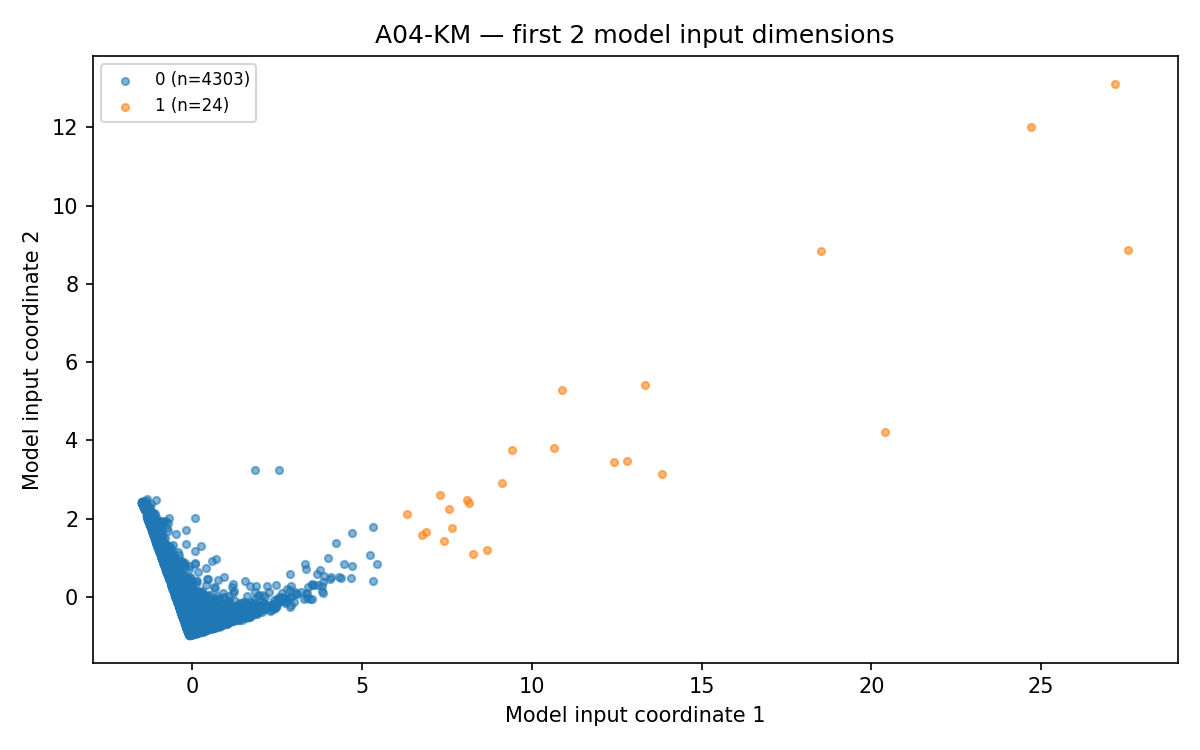

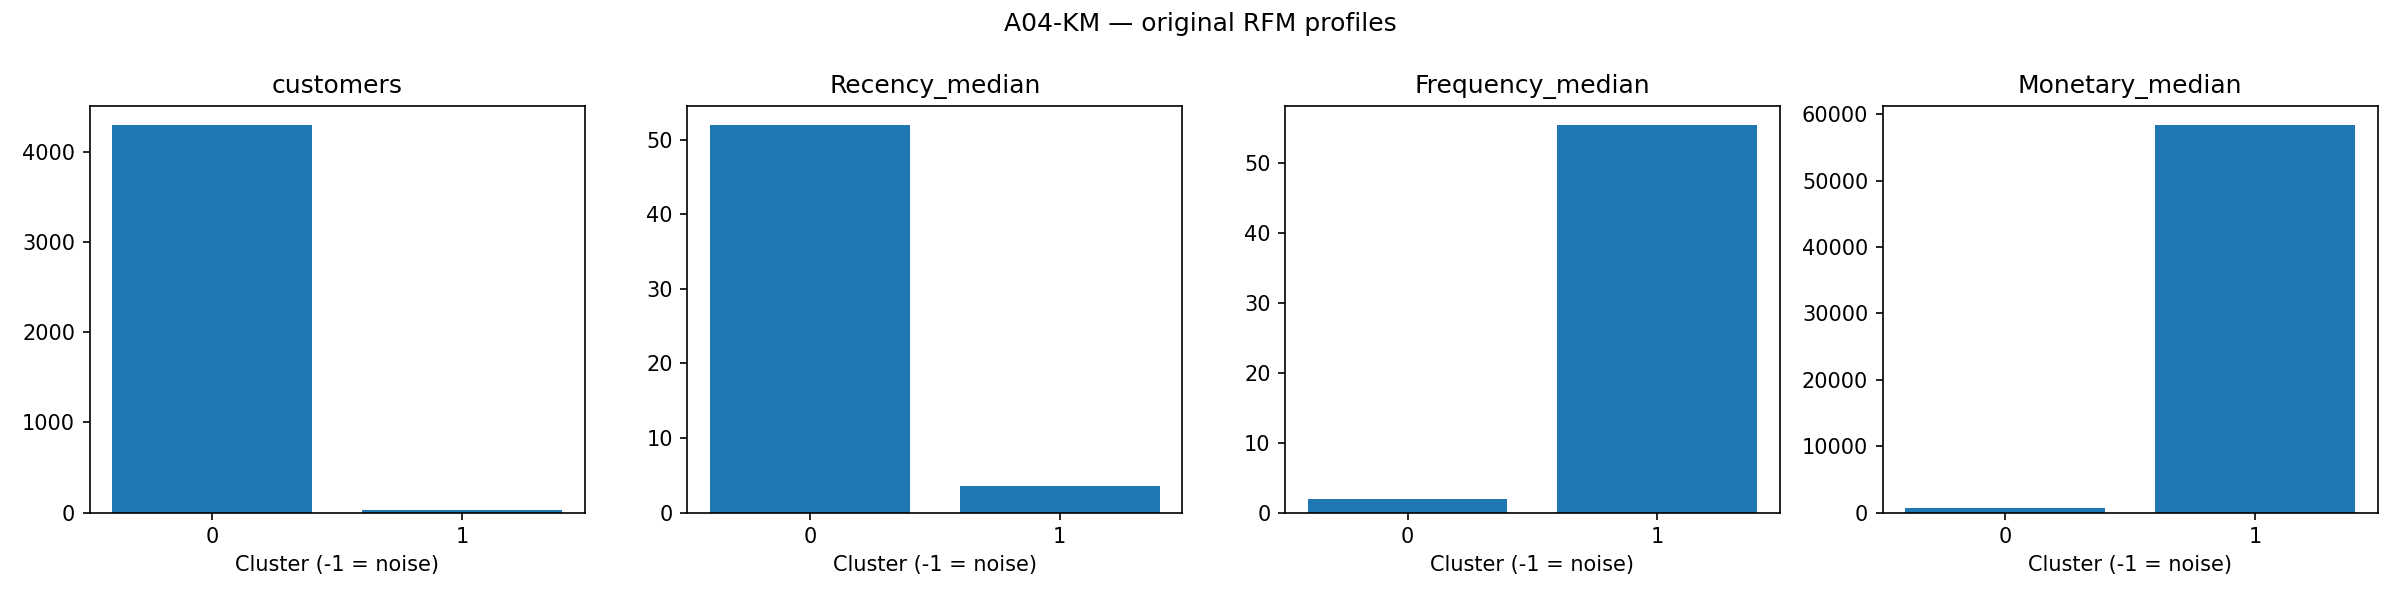

In [4]:
labels = pd.read_csv(OUT / "labels.csv", dtype={"CustomerID": str})
profiles = pd.read_csv(OUT / "profiles.csv")
assert labels.CustomerID.is_unique and len(labels) == params["customers"]
display(labels.head(10))
display(profiles)
display(Image(filename=str(OUT / "figures" / "clusters.png")))
display(Image(filename=str(OUT / "figures" / "profiles.png")))
if (OUT / "figures" / "k_distance.png").exists():
    display(Image(filename=str(OUT / "figures" / "k_distance.png")))


## Đối chiếu và giới hạn
Parent diagnostic giữ tham số đã chọn ở target, không phải baseline được tune độc lập. GNN dùng đồ thị kNN từ RFM, nên AUC/AP liên kết chỉ đánh giá tái dựng graph; không có BIC/AIC. GNN có tính transductive: suy luận chỉ áp dụng tập khách gốc đúng thứ tự.

In [5]:
if params.get("comparison"):
    print(json.dumps(params["comparison"], ensure_ascii=False, indent=2))
print("Chỉ số trên StandardScaler(RFM gốc), dùng cùng không gian tham chiếu:")
display(pd.Series(params["all_customers_common_space_scores"]).to_frame("Giá trị"))
display(Markdown("\n".join("- " + note for note in params["limitations"])))


{
  "parent_configuration": "A01",
  "purpose": "fixed-parameter preprocessing diagnostic, not a tuned parent experiment",
  "target_dimensions": 3,
  "parent_dimensions": 3,
  "ari": 1.0,
  "target_common_rfm_scores": {
    "n_clusters": 2,
    "noise_pct": 0.0,
    "smallest_cluster": 24,
    "largest_cluster_pct_all": 99.44534319389878,
    "silhouette": 0.8993587821096044,
    "dbi": 0.7274616155492135,
    "chi": 1947.5218339357023
  },
  "parent_common_rfm_scores": {
    "n_clusters": 2,
    "noise_pct": 0.0,
    "smallest_cluster": 24,
    "largest_cluster_pct_all": 99.44534319389878,
    "silhouette": 0.8993587821096044,
    "dbi": 0.7274616155492135,
    "chi": 1947.5218339357023
  },
  "parent_input_scores": {
    "n_clusters": 2,
    "noise_pct": 0.0,
    "smallest_cluster": 24,
    "largest_cluster_pct_all": 99.44534319389878,
    "silhouette": 0.8993587821096044,
    "dbi": 0.7274616155492134,
    "chi": 1947.5218339357039
  },
  "parent_preprocessing": {
    "configuratio

,Giá trị
n_clusters,2.000000
noise_pct,0.000000
smallest_cluster,24.000000
largest_cluster_pct_all,99.445343
silhouette,0.899359
dbi,0.727462
chi,1947.521834


- Exploratory clustering, not future value prediction; Monetary is historical sales, not profit.
- No ground-truth labels or held-out predictive evaluation.
- Internal scores from different feature spaces and DBSCAN subsets are not directly comparable.
- The cleaning policy reproduces the shared group RFM; it is not a newly approved official policy.
- Largest cluster contains at least 90% of customers; high Silhouette alone does not imply a useful segmentation.
- A selected cluster contains less than 1% of customers; inspect profiles before use.

## Kiểm tra mô hình đã lưu

In [6]:
import joblib
pipeline = joblib.load(OUT / "pipeline.joblib")
X = labels[runner.FEATURES]
Z = pipeline["preprocessing"].transform(X)
saved = pd.read_csv(OUT / "model_input.csv").filter(like="input_").to_numpy()
np.testing.assert_allclose(Z, saved, atol=1e-9, rtol=0)
if params["actual_model"] != "DBSCAN":
    np.testing.assert_array_equal(pipeline.predict(X), labels.cluster)
else:
    np.testing.assert_array_equal(pipeline["model"].labels_, labels.cluster)
    print("DBSCAN không có predict cho khách mới; labels_ gắn với đúng thứ tự khách khi fit.")
print("PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.")


PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.
